# 03 · 候选 uplift 模型与 validation 选型

## 本页要回答什么

项目有哪些候选模型？模型分数如何进入策略排序？最终策略和 uplift 候选是如何在 validation 上冻结的？

## 代码导航

- 模型定义与工厂：criteo_uplift/models.py 的 make_model()。
- 训练与冻结选型：criteo_uplift/training.py 的 fit_and_select_models()。
- 排序指标：criteo_uplift/evaluation.py 的 ranking_metrics()。
- 结果文件：validation_policies.csv、validation_ranking.csv、selection.json、模型 .joblib 文件、calibration_*.csv。

本页先看候选模型与验证集证据，再看冻结选择。通用 S/T/X learner 原理请查 DSDAHANDBOOK；本页只解释本仓库的实现与结果。

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from criteo_uplift.pipeline_io import result_directory
RUN = result_directory('conversion_1000000_seed42', ROOT)
print('读取结果目录:', RUN.relative_to(ROOT))
manifest = json.loads(((RUN / 'manifest.json')).read_text())
print('分析对象:', manifest['primary_outcome'], '| 随机样本:', f"{manifest['sample_n']:,}")
print('seed:', manifest['seed'], '| 主预算:', manifest['selection']['primary_budget'])


读取结果目录: artifacts/conversion_1000000_seed42
分析对象: conversion | 随机样本: 1,000,000
seed: 42 | 主预算: 0.2


## 候选模型与实现边界

当前候选为 S-Logistic、T-Logistic、T-XGBoost、X-XGBoost；同时比较随机排序与 response propensity 基线。模型类集中在 models.py，训练、验证和冻结选择集中在 training.py。

阅读顺序：先看 models.make_model() 如何创建模型，再看 training.fit_and_select_models() 如何只用 train 拟合、只用 validation 选择。response propensity 是强基线，不等于 treatment assignment probability。

In [2]:
# 只展示模型类型、训练耗时和常见配置，避免把所有 sklearn 参数铺成一张超宽表。
model_rows = []
for name, info in manifest['models'].items():
    params = info.get('parameters', {})
    model_rows.append({
        'model': name,
        'fit_seconds': info.get('seconds'),
        'n_estimators': params.get('n_estimators'),
        'max_depth': params.get('max_depth'),
        'learning_rate': params.get('learning_rate'),
        'C': params.get('C'),
    })
model_table = pd.DataFrame(model_rows).set_index('model')
display(model_table.style.format({'fit_seconds': '{:.2f}'}))

validation = pd.read_csv((RUN / 'models' / 'validation_policies.csv'))
display(validation[['policy', 'budget', 'incremental_per_100k']].sort_values('incremental_per_100k', ascending=False))

,fit_seconds,n_estimators,max_depth,learning_rate,C
model,,,,,
s_logistic,0.45,nan,nan,nan,1.000000
t_logistic,0.46,nan,nan,nan,1.000000
t_xgboost,0.77,150.000000,4.000000,0.050000,nan
x_xgboost,1.50,150.000000,4.000000,0.050000,nan


,policy,budget,incremental_per_100k
5,propensity,0.2,134.930689
1,s_logistic,0.2,133.166833
2,t_logistic,0.2,129.300871
3,t_xgboost,0.2,116.398163
4,x_xgboost,0.2,105.597563
0,random,0.2,25.283487


## 排序指标的实现位置与使用边界

本页读取 validation_ranking.csv、test_ranking.csv 并展示 ranking.png。指标计算在 evaluation.py 的 ranking_metrics()、uplift_curve()；测试阶段的结果由 holdout_evaluation.py 保存。

项目同时保留 HT 与传统 plug-in / Qini 口径。不要只看一个面积数字，也不要将不同估计口径的面积直接混用。具体公式与理论解释请查 DSDAHANDBOOK；本页关注结果文件里的字段和本项目选型规则。

Validation ranking


,policy,auuc_ht,qini_ht,auuc_plugin,qini_score_traditional
0,s_logistic,0.001261,0.000629,0.001176,0.000469
1,t_logistic,0.001267,0.000635,0.001186,0.000478
2,t_xgboost,0.001073,0.000441,0.001011,0.000327
3,x_xgboost,0.000995,0.000362,0.000934,0.000261


Frozen test ranking


,policy,auuc_ht,qini_ht,auuc_plugin,qini_score_traditional
0,propensity,0.001198,0.000583,0.001137,0.000448
1,s_logistic,0.001196,0.000580,0.001132,0.000444
2,t_logistic,0.001210,0.000595,0.001148,0.000458
3,t_xgboost,0.000972,0.000357,0.000912,0.000256
4,x_xgboost,0.001099,0.000484,0.001057,0.000379


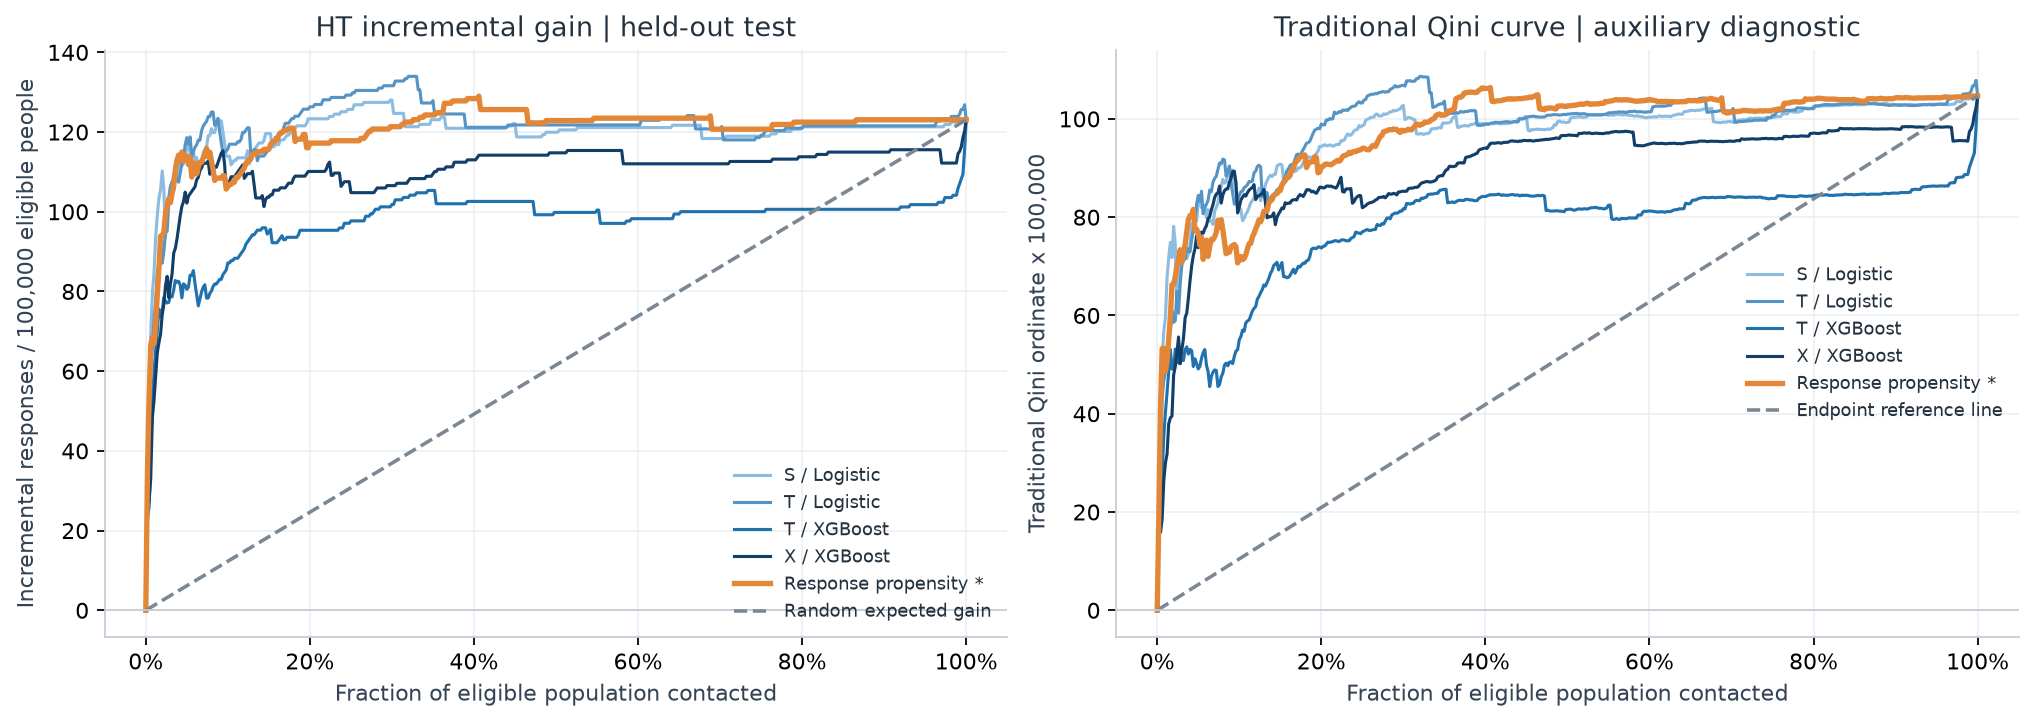

In [3]:
# validation 与 test 排序结果分开展示；test 只用于报告冻结模型的表现，不回头选型。
ranking_columns = [
    'policy', 'auuc_ht', 'qini_ht', 'auuc_plugin',
    'qini_score_traditional', 'relative_lift', 'incremental_per_100k'
]
for label, folder, filename in [
    ('Validation ranking', 'models', 'validation_ranking.csv'),
    ('Frozen test ranking', 'evaluation', 'test_ranking.csv'),
]:
    ranking = pd.read_csv(RUN / folder / filename)
    columns = [column for column in ranking_columns if column in ranking.columns]
    print(label)
    display(ranking[columns].sort_values('policy').reset_index(drop=True))
display(Image(filename=str(RUN / 'figures/ranking.png')))

## CATE 校准诊断

**实现位置：** evaluation.py 的 calibration_table()；测试阶段由 holdout_evaluation.py 保存 calibration_*.csv。

分箱结果用于检查预测分数与组间观测差异是否呈现一致趋势。它不是个体真实反事实标签，因此不能据此报告真实 PEHE/ITE MSE；全局均值接近 ATE 也不能证明个体排序正确。测试集诊断不会用于重新校准当前模型。

Validation 冻结的最佳 uplift 候选（不一定是最终策略）: s_logistic


,bin,n,n_treatment,n_control,predicted_cate,prediction_min,prediction_max,observed_ate,standard_error,ci_low,ci_high
0,1,20000,16968,3032,0.000106,0.000045,0.000123,0.000177,0.000102,-0.000023,0.000377
1,2,20000,16974,3026,0.000131,0.000123,0.000139,0.000000,0.000000,0.000000,0.000000
2,3,20000,16938,3062,0.000147,0.000139,0.000154,0.000295,0.000132,0.000036,0.000554
3,4,20000,16890,3110,0.000162,0.000154,0.000170,-0.000262,0.000327,-0.000903,0.000378
4,5,20000,17049,2951,0.000181,0.000170,0.000194,0.000117,0.000083,-0.000045,0.000280
5,6,20000,16973,3027,0.000211,0.000194,0.000233,-0.000095,0.000351,-0.000782,0.000593
6,7,20000,16948,3052,0.000264,0.000233,0.000302,-0.000688,0.000582,-0.001830,0.000454
7,8,20000,16972,3028,0.000362,0.000302,0.000445,0.000471,0.000167,0.000145,0.000798
8,9,20000,17095,2905,0.000675,0.000445,0.001116,0.000898,0.000684,-0.000443,0.002238
9,10,20000,17275,2725,0.008981,0.001116,0.138409,0.009438,0.002780,0.003990,0.014886


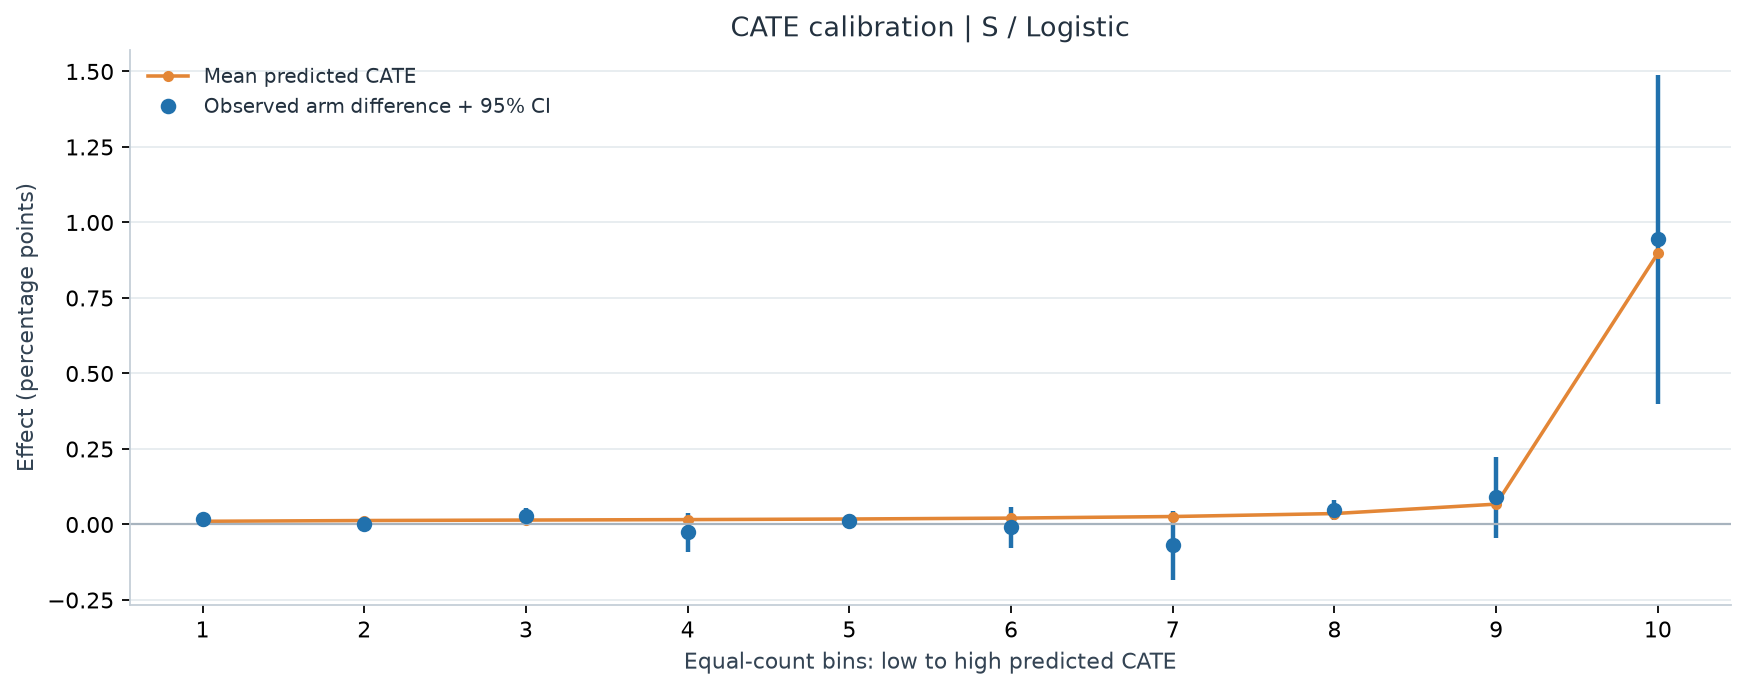

In [4]:
chosen_uplift = manifest['selection']['selected_uplift_model']
print('Validation 冻结的最佳 uplift 候选（不一定是最终策略）:', chosen_uplift)
calibration = pd.read_csv((RUN / 'evaluation' / f'calibration_{chosen_uplift}.csv'))
display(calibration.head(12))
display(Image(filename=str(RUN / 'figures/calibration.png')))

## 模型复用与部署边界

模型定义位于 models.py，训练与冻结选择位于 training.py。已训练模型保存在当前结果目录的 .joblib 文件中；只加载本项目可信文件。

~~~python
from criteo_uplift.models import make_model
model = make_model('x_xgboost', random_state=42, n_estimators=150)
model.fit(train[FEATURES], train.treatment, train.conversion)
tau = model.predict(new_users[FEATURES])
~~~

对新特征文件生成离线预算名单的入口是 score_policy.py。它不重新训练或重新选型；输入至少包含 f0–f11，输入文件保持只读，输出不得写入 data/。

Pipeline 和结果文件的完整映射见 ../docs/PROJECT_PIPELINE.md 与 ../docs/RESULTS_GUIDE.md。